# 07. Feature Engineering and Feature Selection

**Before this notebook:** read `notes/07_feature_engineering_and_selection.md`.

**Goal:** create a few useful new features, measure how informative every feature is (using the **training set only**), and decide which weak ones to drop. The result is one reusable function, saved in `src/features.py`, that the pipeline in notebook 08 will use.

**Steps**
1. Load the split
2. Engineering idea on a tiny example
3. Build the new features
4. Check each new feature against churn
5. A rejected idea: a redundant feature
6. Feature selection with mutual information (train only)
7. Apply the decisions and check the result
8. Exercise

## Step 1: Load the split and our helper module

Notebook 06 explained why we only learn from the training data. Same rule here.

In [1]:
import sys
sys.path.append("../..")          # lets Python find the project's src/ folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

from src.features import add_features, drop_weak_features, engineer, ADDON_COLS, DROP_COLS

sns.set_theme(style="whitegrid")
DATA = Path("../../data/processed")
FIG_DIR = Path("../../reports/figures")

X_train = pd.read_csv(DATA / "X_train.csv")
X_test  = pd.read_csv(DATA / "X_test.csv")
y_train = pd.read_csv(DATA / "y_train.csv").squeeze()

print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


**Line by line**
- `sys.path.append("../..")`: tells Python to also look two folders up (the project root), so `from src.features import ...` works from inside the notebook folder.
- We import our own functions from `src/features.py`. Open that file and read it. It is short, and every function is explained by its comments.
- We **do not load `y_test`**. Feature decisions must never involve test labels.

**Expected output:** `(5634, 19) (1409, 19)`.

## Step 2: The idea on a tiny example

The 3-customer example from the notes: count how many add-on services each customer has.

In [2]:
mini = pd.DataFrame({
    "OnlineSecurity": ["No", "Yes", "No"],
    "TechSupport":    ["No", "Yes", "Yes"],
})

print((mini == "Yes").sum(axis=1).tolist())

[0, 2, 1]


**Line by line**
- `mini == "Yes"`: a table of True/False, one cell per original cell.
- `.sum(axis=1)`: adds across each **row** (`axis=1`; `axis=0` would add down each column). True counts as 1.

**How to read the output:** `[0, 2, 1]`: customer 1 has no add-ons, customer 2 has both, customer 3 has one. This is the feature we build for real next.

## Step 3: Build the new features

Open `src/features.py` to see `add_features`. It creates three columns:

| New feature | Idea | Why it might matter |
|---|---|---|
| `num_addons` | How many of the 6 add-ons the customer pays for | Customers using more services are more "attached" |
| `is_autopay` | Payment method contains "automatic" | Automatic payment means less friction. EDA showed electronic-check payers churn most |
| `tenure_group` | Bins: 0-12, 13-24, 25-48, 49-72 months | Churn falls with stage of relationship, not in a straight line |

In [3]:
X_train_new = add_features(X_train)
X_test_new  = add_features(X_test)      # same rule-based function: no leakage

new_cols = ["num_addons", "is_autopay", "tenure_group"]
X_train_new[["tenure", "PaymentMethod"] + ADDON_COLS[:2] + new_cols].head()

,tenure,PaymentMethod,OnlineSecurity,OnlineBackup,num_addons,is_autopay,tenure_group
0,35,Electronic check,No,No,3,0,25-48
1,15,Mailed check,Yes,No,1,0,13-24
2,13,Mailed check,Yes,Yes,3,0,13-24
3,26,Credit card (automatic),No,Yes,4,1,25-48
4,1,Electronic check,No,No,0,0,0-12


**Line by line**
- `add_features(X_train)` returns a *copy* with three extra columns. The original `X_train` is unchanged.
- We apply the **same function** to the test set. It is rule-based: it looks at one row at a time and learns nothing, so it cannot leak.
- The last line shows a few original columns next to the new ones so you can verify by eye that the rule works. For example, look at a row's `tenure` and check that its `tenure_group` matches, and that `is_autopay` is 1 only for the "automatic" payment methods.

**Always check a new feature by hand on a few rows.** A bug here would silently spread to every later notebook.

## Step 4: Check each new feature against churn

Does the new feature actually relate to the target? We compute the churn rate per group on the **training** set.

In [4]:
def churn_rate(feature, data=X_train_new, target=y_train):
    # mean of the 0/1 target per group = churn rate in percent
    return (target.groupby(data[feature]).mean() * 100).round(1)

for f in ["tenure_group", "is_autopay", "num_addons"]:
    print(f"--- {f} ---")
    print(churn_rate(f).to_string())
    print()

--- tenure_group ---
tenure_group
0-12     47.3
13-24    28.6
25-48    20.2
49-72     9.9

--- is_autopay ---
is_autopay
0    35.0
1    15.5

--- num_addons ---
num_addons
0    20.9
1    45.8
2    36.2
3    27.8
4    23.0
5    12.5
6     4.7



**Line by line**
- `target.groupby(data[feature]).mean()`: groups the 0/1 target by the feature's values and averages, giving the churn rate per group. (We pass a column as the grouping key, since the target is a separate Series.)

**How to read the output**
- **`tenure_group`:** about **47 %** churn in the first year, falling to about **10 %** after four years. A clear, steady pattern.
- **`is_autopay`:** about **35 %** churn for non-automatic payers vs. about **16 %** for automatic payers. A real difference.
- **`num_addons`:** surprising! 0 add-ons has a *low* churn rate (about 21 %), while 1 add-on has the *highest* (about 46 %), and then the rate falls. That is not a smooth pattern. Why? Let's investigate before trusting it.

In [5]:
has_internet = X_train_new["InternetService"] != "No"

print("Customers WITHOUT internet:", (~has_internet).sum())
print("Their churn rate:", round(y_train[~has_internet].mean() * 100, 1), "%")
print()
print("Churn rate by num_addons, only customers WITH internet:")
print(churn_rate("num_addons", X_train_new[has_internet], y_train[has_internet]).to_string())

Customers WITHOUT internet: 1214
Their churn rate: 7.2 %

Churn rate by num_addons, only customers WITH internet:
num_addons
0    51.6
1    45.8
2    36.2
3    27.8
4    23.0
5    12.5
6     4.7


**Line by line**
- `has_internet`: a True/False Series that marks customers who have an internet service.
- `~has_internet`: the `~` flips it, selecting customers **without** internet.
- We pass subsets of both the data and the target (same mask, so rows stay aligned).

**How to read the output**
- Customers without internet (about 1,200 in training) can have **no add-ons at all**, because add-ons are internet services. They automatically get `num_addons = 0`, and they churn very little (about 7 %).
- That group is **mixed into** the `num_addons = 0` bucket and drags its churn rate down. This is called **confounding**: two different groups hidden inside one value.
- Among internet customers only, churn **falls steadily** as add-ons increase, from roughly 50 % for none to a few percent for six, which is the intuitive pattern.

**What to do?** The model also has `InternetService` as a feature, so it can tell the "no internet" group apart. We **keep** `num_addons`. The lesson: always investigate a strange pattern before trusting or rejecting a feature.

## Step 5: A rejected idea: a redundant feature

Idea: average monthly spend so far = `TotalCharges / tenure`. Does it add anything beyond `MonthlyCharges`?

In [6]:
avg_spend = np.where(
    X_train["tenure"] > 0,
    X_train["TotalCharges"] / X_train["tenure"].replace(0, 1),   # replace(0,1) avoids dividing by zero
    X_train["MonthlyCharges"],                                    # new customers: use their monthly price
)

print("Correlation with MonthlyCharges:", round(np.corrcoef(avg_spend, X_train["MonthlyCharges"])[0, 1], 3))

Correlation with MonthlyCharges: 0.996


**Line by line**
- `np.where(condition, value_if_true, value_if_false)`: chooses per row. When `tenure > 0` we divide the total by the months. For new customers (tenure 0) division would fail, so we use their monthly price.
- `np.corrcoef(a, b)[0, 1]`: the correlation between two lists of numbers.

**How to read the output:** correlation is about **1.0**. Most customers pay the same price every month, so "average spend so far" is practically `MonthlyCharges` again. It carries **no new information**, so we **do not add it**.

Not every idea works, and checking is how you find out cheaply.

## Step 6: Feature selection with mutual information (training set only)

**Mutual information (MI)** scores how informative each feature is about the target. 0 means "tells nothing", higher means more informative. Because the score is learned from the target, we compute it on the **training set only**.

`mutual_info_classif` needs numbers, so we first turn categories into integer codes, only for this scoring. (This is not the final encoding. The pipeline will use one-hot.)

In [7]:
Z = X_train_new.copy()
cat_cols = Z.select_dtypes(exclude="number").columns.tolist()

# Integer codes for the text columns (fitted on training data only)
Z[cat_cols] = OrdinalEncoder().fit_transform(Z[cat_cols])

# Tell the function which columns are discrete (categories / small counts) vs continuous
continuous = ["tenure", "MonthlyCharges", "TotalCharges"]
discrete_mask = [c not in continuous for c in Z.columns]

mi = pd.Series(
    mutual_info_classif(Z, y_train, discrete_features=discrete_mask, random_state=42),
    index=Z.columns,
).sort_values(ascending=False)

print(mi.round(3).to_string())

Contract            0.099
tenure              0.079
OnlineSecurity      0.066
TechSupport         0.064
tenure_group        0.060
InternetService     0.057
MonthlyCharges      0.048
OnlineBackup        0.047
PaymentMethod       0.047
DeviceProtection    0.044
TotalCharges        0.040
StreamingMovies     0.032
StreamingTV         0.032
num_addons          0.030
is_autopay          0.025
PaperlessBilling    0.020
Dependents          0.015
Partner             0.011
SeniorCitizen       0.010
MultipleLines       0.001
PhoneService        0.000
gender              0.000


**Line by line**
- `OrdinalEncoder().fit_transform(Z[cat_cols])`: gives each category an integer code. Fine **for scoring only**, even for nominal categories, because MI treats them as labels, not as quantities.
- `discrete_mask`: a list of True/False that tells `mutual_info_classif` which columns are categories and which are continuous. It uses different estimators for each.
- `random_state=42`: continuous MI uses a small amount of randomness, so we fix the seed to get the same numbers each run.
- `mutual_info_classif(X, y)`: *input:* features and target. *Output:* one MI score per feature.
- `.sort_values(ascending=False)`: most informative first.

**How to read the output** (numbers vary slightly if you change the seed)
- At the top: `Contract` (about 0.10), `tenure`, `OnlineSecurity`, `TechSupport`. This agrees with EDA: contract type and tenure were the strongest signals.
- Our new `tenure_group` scores well (about 0.06), but a little lower than `tenure` itself, since it is a coarser version of it.
- At the bottom: **`gender`, `PhoneService` and `MultipleLines` are about 0.00**: they say practically nothing about churn. EDA showed the same for `gender`.

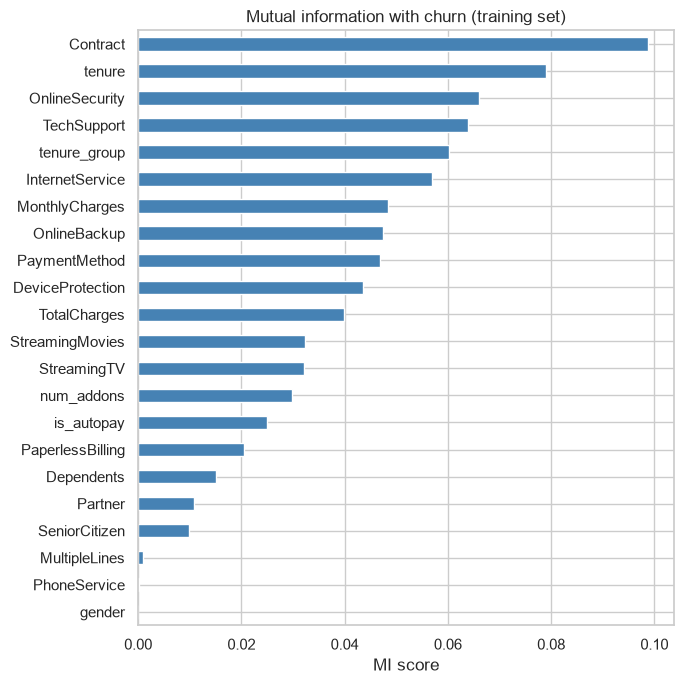

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))
mi.sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Mutual information with churn (training set)")
ax.set_xlabel("MI score")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_mutual_information.png", dpi=120)
plt.show()

**How to read the chart:** a clear gap separates the strongly informative features at the top from a tail of weak ones. The three at the very bottom are our removal candidates.

**Caution** (from the notes): MI looks at each feature **alone**. A feature with MI near 0 could still matter in combination with others, so this is evidence, not proof. We take a low-risk approach: drop only the three that are close to zero **and** had no pattern in EDA. We keep every other feature, even moderately weak ones, because removing them costs little to avoid and might hurt. In later notebooks we compare model scores to confirm the drop was harmless.

## Step 7: Apply the decisions and check the result

`engineer()` in `src/features.py` does both: adds the three features, then drops the three weak ones. This single function is what the pipeline will call, for training, for testing, and for brand-new customers.

In [9]:
print("Dropping:", DROP_COLS)

X_train_fe = engineer(X_train)
X_test_fe  = engineer(X_test)

print("Before:", X_train.shape, "-> After:", X_train_fe.shape)
assert list(X_train_fe.columns) == list(X_test_fe.columns), "train/test columns differ!"
print("Train and test have identical columns.")
print()
print("New columns:", [c for c in X_train_fe.columns if c not in X_train.columns])

Dropping: ['gender', 'PhoneService', 'MultipleLines']
Before: (5634, 19) -> After: (5634, 19)
Train and test have identical columns.

New columns: ['num_addons', 'is_autopay', 'tenure_group']


**Line by line**
- `engineer(...)` = `drop_weak_features(add_features(...))`: added 3 columns, removed 3, so the column count stays at **19**, with different content.
- The `assert` guarantees that train and test have exactly the same columns in the same order. The model will require this.

**Expected output:** `(5634, 19) -> (5634, 19)`, identical columns, and the new columns `['num_addons', 'is_autopay', 'tenure_group']`.

The function also works for a **single new customer**, which is how it will be used in production:

In [10]:
new_customer = X_train.iloc[[0]].copy()              # one row, as a table
print(engineer(new_customer)[["tenure", "tenure_group", "num_addons", "is_autopay"]])

   tenure tenure_group  num_addons  is_autopay
0      35        25-48           3           0


**Line by line:** `iloc[[0]]` (double brackets) selects the first row but keeps it as a one-row **table**, which is the shape the function expects.

**How to read the output:** the engineered columns are computed for the new row with no information from any other row.

## Summary

| Decision | Result | Evidence |
|---|---|---|
| Add `tenure_group` | Kept | Churn 47 % → 10 % across groups |
| Add `is_autopay` | Kept | Churn 35 % vs 16 % |
| Add `num_addons` | Kept (confounded by "no internet") | Falls steadily among internet customers |
| Add `avg monthly spend` | **Rejected** | Correlation about 1.0 with `MonthlyCharges` |
| Drop `gender`, `PhoneService`, `MultipleLines` | Dropped | MI about 0, no pattern in EDA |
| Keep `TotalCharges` (overlaps `tenure`, r = 0.83) | Kept | Trees are unaffected. We will watch Logistic Regression |

**Final feature set:** 19 columns, produced by `src/features.py: engineer()`.

**Next:** `08_pipelines`: connect engineering, encoding and scaling into one scikit-learn **Pipeline**, so everything is fitted on training data only and applied identically to test data and new customers.

---
## Exercise

1. Write a new rule-based feature `is_new_customer` (1 if `tenure <= 6`). Compute its churn rate for 0 and 1 on the training set.
2. Compute MI for your new feature the same way as in Step 6. Is it more or less informative than `tenure_group`?
3. In `src/features.py`, add your feature inside `add_features`, rerun Step 3 and Step 7, and confirm train and test still have identical columns.
4. **Think:** a friend suggests the feature "average churn rate of the customer's Contract type". Why is that target leakage?

In [11]:
# Exercise 1

In [12]:
# Exercise 2